# <Center> INF - Deliverable 1

<center> Group: Magnus Bigum and Georg Hagen
<center> Date: 16.10.2026

# Task 1: Temperature

In [ ]:
import pandas as pd

import requests

import matplotlib.pyplot as plt 

client_id = open('frost_client_id.txt').read().strip()


# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])

rows=[]

for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)

df = pd.concat(rows, ignore_index=True)




In [18]:

def temperature_summary(df):
    summary = pd.DataFrame({
        "Statistics": ["Mean", "Median", "min", "max"],
        "Temperature (°C)": [
            df["value"].mean(),
            df["value"].median(),
            df["value"].min(),
            df["value"].max()
        ]
    })

    print("Temperature Summary - 2025")
    print(summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    ))

temperature_summary(df)



Temperature Summary - 2025
Statistics  Temperature (°C)
      Mean              7.90
    Median              8.35
       min            -16.10
       max             24.50


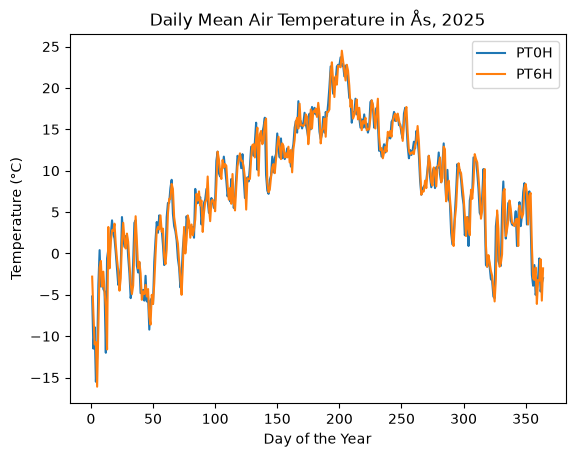

In [20]:
df_pt0h = df[df["timeOffset"] == "PT0H"].copy()
df_pt0h.index = range(1, len(df_pt0h) + 1)

df_pt6h = df[df["timeOffset"] == "PT6H"].copy()
df_pt6h.index = range(1, len(df_pt6h) + 1)

fig, ax = plt.subplots()

df_pt0h.plot(y="value", ax=ax, label="PT0H")
df_pt6h.plot(y="value", ax=ax, label="PT6H")

ax.set_title("Daily Mean Air Temperature in Ås, 2025")
ax.set_xlabel("Day of the Year")
ax.set_ylabel("Temperature (°C)")
ax.legend()

plt.show()